In [2]:
import sys
import platform
import tensorflow as tf

print("Python:", sys.executable)
print("Architecture:", platform.machine())
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Python: /Users/prernamallawat/Desktop/Albany/Fall 2026/AI/Medical-Image-Classification/.venv/bin/python
Architecture: arm64
TensorFlow: 2.21.0
GPU: []


In [3]:
from pathlib import Path
import numpy as np

PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed_224_pad_gray"

def load_split(name):
    with np.load(PROCESSED_DIR / f"{name}.npz") as data:
        X = data["images"].astype(np.float32) / 255.0
        y = data["labels"].astype(np.int64)
    return X, y

X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")
X_test, y_test = load_split("test")

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (4181, 224, 224) (4181,)
Validation: (1051, 224, 224) (1051,)
Test: (624, 224, 224) (624,)


In [4]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

dense_model = keras.Sequential([
    keras.Input(shape=(224, 224)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

dense_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

dense_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,422,785 (24.50 MB)

 Trainable params: 6,422,785 (24.50 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
from pathlib import Path

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        MODEL_DIR / "dense_baseline.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True
    )
]

history = dense_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.7812 - auc: 0.8184 - loss: 1.0049 - val_accuracy: 0.8611 - val_auc: 0.9248 - val_loss: 0.3852
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.8268 - auc: 0.8887 - loss: 0.3556 - val_accuracy: 0.9068 - val_auc: 0.9489 - val_loss: 0.2875
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.8551 - auc: 0.9190 - loss: 0.3053 - val_accuracy: 0.9248 - val_auc: 0.9747 - val_loss: 0.2203
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8661 - auc: 0.9325 - loss: 0.2801 - val_accuracy: 0.8706 - val_auc: 0.9680 - val_loss: 0.3283
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.8433 - auc: 0.9213 - loss: 0.2938 - val_accuracy: 0.9096 - val_auc: 0.9638 - val_loss: 0.2235
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.8807 - auc: 0.9444 - loss: 0.2511 - val_accuracy: 0.9277 - val_auc: 0.9803 - val_loss: 0.1979
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━

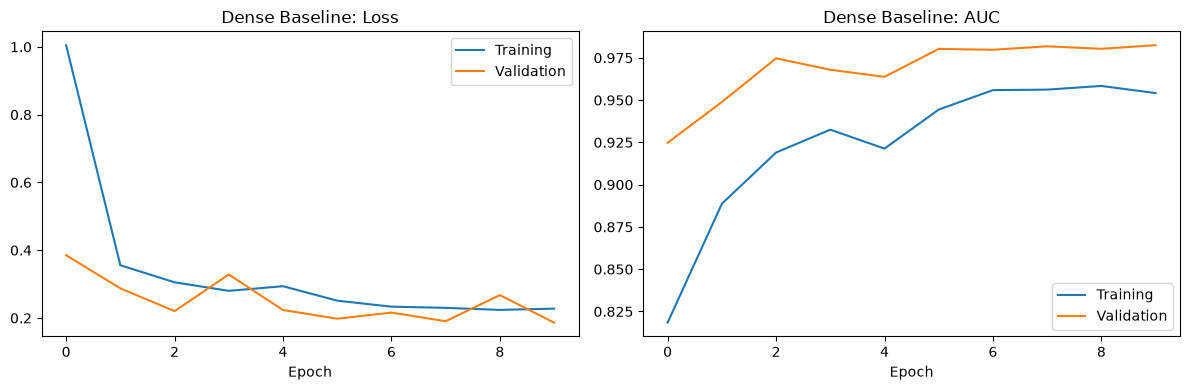

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set_title("Dense Baseline: Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["auc"], label="Training")
axes[1].plot(history.history["val_auc"], label="Validation")
axes[1].set_title("Dense Baseline: AUC")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [7]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

best_model = tf.keras.models.load_model(
    MODEL_DIR / "dense_baseline.keras"
)

val_prob = best_model.predict(X_val, verbose=0).ravel()
val_pred = (val_prob >= 0.5).astype(int)

print("Validation AUC:", round(roc_auc_score(y_val, val_prob), 4))
print("Validation accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_val, val_pred))
print("\nClassification report:")
print(classification_report(
    y_val,
    val_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

Validation AUC: 0.983
Validation accuracy: 0.9286

Confusion matrix:
[[202  66]
 [  9 774]]

Classification report:
              precision    recall  f1-score   support

      NORMAL       0.96      0.75      0.84       268
   PNEUMONIA       0.92      0.99      0.95       783

    accuracy                           0.93      1051
   macro avg       0.94      0.87      0.90      1051
weighted avg       0.93      0.93      0.93      1051



NORMAL probability predictions:
Min: 0.038755115
Median: 0.28844905
Max: 0.9996609

PNEUMONIA probability predictions:
Min: 0.18749487
Median: 0.99920297
Max: 1.0


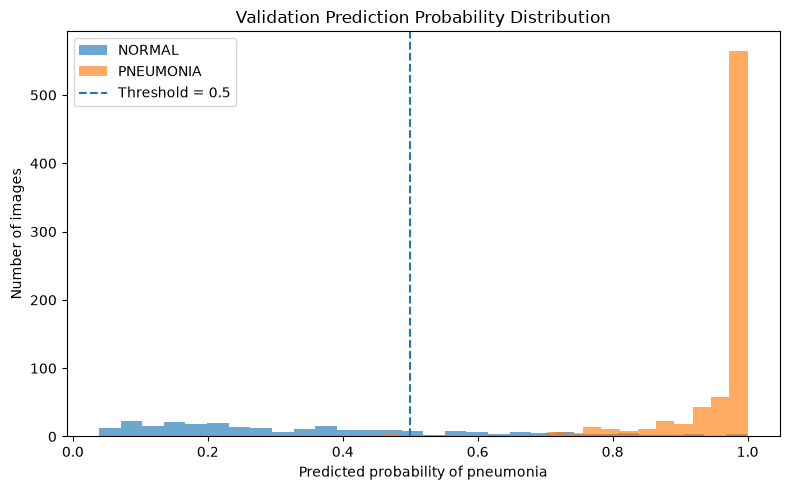

In [8]:
import numpy as np
import matplotlib.pyplot as plt

normal_probs = val_prob[y_val == 0]
pneumonia_probs = val_prob[y_val == 1]

print("NORMAL probability predictions:")
print("Min:", normal_probs.min())
print("Median:", np.median(normal_probs))
print("Max:", normal_probs.max())

print("\nPNEUMONIA probability predictions:")
print("Min:", pneumonia_probs.min())
print("Median:", np.median(pneumonia_probs))
print("Max:", pneumonia_probs.max())

plt.figure(figsize=(8, 5))
plt.hist(normal_probs, bins=30, alpha=0.65, label="NORMAL")
plt.hist(pneumonia_probs, bins=30, alpha=0.65, label="PNEUMONIA")
plt.axvline(0.5, linestyle="--", label="Threshold = 0.5")
plt.xlabel("Predicted probability of pneumonia")
plt.ylabel("Number of images")
plt.title("Validation Prediction Probability Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import confusion_matrix

for threshold in [0.50, 0.70, 0.80, 0.90, 0.95, 0.99]:
    pred = (val_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_val, pred, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if tp + fn else 0
    specificity = tn / (tn + fp) if tn + fp else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    print(
        f"Threshold={threshold:.2f} | "
        f"Accuracy={accuracy:.3f} | "
        f"Sensitivity={sensitivity:.3f} | "
        f"Specificity={specificity:.3f}"
    )

Threshold=0.50 | Accuracy=0.929 | Sensitivity=0.989 | Specificity=0.754
Threshold=0.70 | Accuracy=0.950 | Sensitivity=0.974 | Specificity=0.877
Threshold=0.80 | Accuracy=0.934 | Sensitivity=0.932 | Specificity=0.940
Threshold=0.90 | Accuracy=0.892 | Sensitivity=0.865 | Specificity=0.970
Threshold=0.95 | Accuracy=0.834 | Sensitivity=0.783 | Specificity=0.985
Threshold=0.99 | Accuracy=0.743 | Sensitivity=0.656 | Specificity=0.996


In [10]:
from sklearn.metrics import roc_auc_score, accuracy_score

train_prob = best_model.predict(X_train, verbose=0).ravel()
train_pred = (train_prob >= 0.5).astype(int)

print("Training AUC:", round(roc_auc_score(y_train, train_prob), 4))
print("Training accuracy:", round(accuracy_score(y_train, train_pred), 4))

Training AUC: 0.9852
Training accuracy: 0.929


In [11]:
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(
        name,
        "| NORMAL:", int((labels == 0).sum()),
        "| PNEUMONIA:", int((labels == 1).sum())
    )

Train | NORMAL: 1081 | PNEUMONIA: 3100
Validation | NORMAL: 268 | PNEUMONIA: 783
Test | NORMAL: 234 | PNEUMONIA: 390


In [12]:
import numpy as np
from sklearn.metrics import roc_curve

# y_val: 0 = NORMAL, 1 = PNEUMONIA
# val_prob: predicted probability of PNEUMONIA

fpr, tpr, thresholds = roc_curve(y_val, val_prob)

specificity = 1 - fpr
target_specificity = 0.95

eligible = np.where(specificity >= target_specificity)[0]

if len(eligible) == 0:
    print("No threshold achieves the target specificity.")
else:
    # Among thresholds meeting the target, maximize sensitivity
    best_idx = eligible[np.argmax(tpr[eligible])]
    selected_threshold = thresholds[best_idx]

    print("Selected threshold:", round(float(selected_threshold), 4))
    print("Validation sensitivity:", round(float(tpr[best_idx]), 4))
    print("Validation specificity:", round(float(specificity[best_idx]), 4))

Selected threshold: 0.835
Validation sensitivity: 0.9183
Validation specificity: 0.9552
